# Project 1 — Level 1: Exploratory Data Analysis on Retail Sales Data
**Internship:** Oasis Infobyte — Data Analytics

## Dataset
**Dataset:** Retail Sales Dataset  
**Source (GitHub mirror):** https://raw.githubusercontent.com/arehmanaziz/100DaysOfBytewise/main/task-10/datasets/retail_sales_dataset.csv  
**Original source (Kaggle):** https://www.kaggle.com/datasets/mohammadtalib786/retail-sales-dataset  
**License / usage:** not stated by the publisher; mirrored here for educational and portfolio use.  
**Expected filename:** `data/raw/retail_sales.csv`  
**Rows / columns:** 1,000 transactions × 9 fields  
**Key columns:** `Transaction ID`, `Date`, `Customer ID`, `Gender`, `Age`, `Product Category`, `Quantity`, `Price per Unit`, `Total Amount`

> Place the downloaded CSV in `DataAnalytics-L1-EDARetailSales/data/raw/retail_sales.csv` before running this notebook. The loader below raises an explicit error with the expected path if the file is missing.

In [1]:

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
warnings.filterwarnings("ignore")

DATASET_FILE = "retail_sales.csv"
DATASET_URL = (
    "https://raw.githubusercontent.com/arehmanaziz/100DaysOfBytewise/"
    "main/task-10/datasets/retail_sales_dataset.csv"
)


def find_project_root(filename, max_up=4):
    """Locate the project folder that owns data/raw/<filename>.

    The search walks up from the working directory (so the notebook runs from
    notebooks/, from the project folder, or from the repository root) and, at
    each level, also looks one level down into sibling project folders. That
    makes it work even when the kernel starts at the repository root.
    """
    here = Path.cwd().resolve()
    for _ in range(max_up):
        if (here / "data" / "raw" / filename).exists():
            return here
        if here.is_dir():
            for child in sorted(here.iterdir()):
                if child.is_dir() and (child / "data" / "raw" / filename).exists():
                    return child
        if here.parent == here:
            break
        here = here.parent
    raise FileNotFoundError(
        "Could not find data/raw/" + filename + " in this folder, any parent folder, "
        "or any sibling project folder.\n"
        "Expected location: <project>/data/raw/" + filename + "\n"
        "Download it from:\n  " + DATASET_URL + "\n"
        "then save it as " + filename + " in the data/raw/ folder of "
        "DataAnalytics-L1-EDARetailSales."
    )


root = find_project_root(DATASET_FILE)
raw = root / "data" / "raw" / DATASET_FILE
print("Project root:", root)
print("Dataset path:", raw)

df = pd.read_csv(raw)
print("Loaded shape:", df.shape)


Project root: C:\Users\sohan\OneDrive\Desktop\OIBSIP\DataAnalytics-L1-EDARetailSales
Dataset path: C:\Users\sohan\OneDrive\Desktop\OIBSIP\DataAnalytics-L1-EDARetailSales\data\raw\retail_sales.csv
Loaded shape: (1000, 9)


## 1. Load and inspect the dataset

In [2]:

print("Columns:", list(df.columns))
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nNull values per column:")
print(df.isnull().sum())
print("\nFirst 5 rows:")
print(df.head().to_string(index=False))


Columns: ['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']
Shape: (1000, 9)

Data types:
Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object

Null values per column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

First 5 rows:
 Transaction ID       Date Customer ID Gender  Age Product Category  Quantity  Price per Unit  Total Amount
              1 2023-11-24     CUST001   Male   34           Beauty         3              50           150
              2 2023-02-27     CUST002 Female   26         Clothing         2             500          1000
             

## 2. Missing values and data-quality checks

In [3]:

print("Duplicate rows:", df.duplicated().sum())
print("\nRows where 'Total Amount' != Quantity * 'Price per Unit':")
bad = df[df["Total Amount"] != df["Quantity"] * df["Price per Unit"]]
print(len(bad))
if len(bad):
    print(bad.head().to_string(index=False))

print("\nInvalid / non-positive values:")
print("  Quantity <= 0        :", (df["Quantity"] <= 0).sum())
print("  Price per Unit <= 0  :", (df["Price per Unit"] <= 0).sum())
print("  Total Amount <= 0    :", (df["Total Amount"] <= 0).sum())
print("  Age outside 18-100   :", ((df["Age"] < 18) | (df["Age"] > 100)).sum())
print("\nCategorical value counts:")
for col in ["Gender", "Product Category"]:
    print(f"\n{col}:")
    print(df[col].value_counts().to_string())


Duplicate rows: 0

Rows where 'Total Amount' != Quantity * 'Price per Unit':
0

Invalid / non-positive values:
  Quantity <= 0        : 0
  Price per Unit <= 0  : 0
  Total Amount <= 0    : 0
  Age outside 18-100   : 0

Categorical value counts:

Gender:
Gender
Female    510
Male      490

Product Category:
Product Category
Clothing       351
Electronics    342
Beauty         307


**Cleaning decision:** the checks above drive the cleaning steps that follow. Every transformation is applied explicitly so its effect on row counts is visible rather than assumed.

In [4]:

rows_before = len(df)

# 1) Drop fully duplicated rows (identical transaction records).
df = df.drop_duplicates().copy()

# 2) Remove rows with non-positive values, which cannot represent a real sale.
df = df[(df["Quantity"] > 0) & (df["Price per Unit"] > 0) & (df["Total Amount"] > 0)].copy()

# 3) Remove rows whose age is outside a plausible adult range.
df = df[(df["Age"] >= 18) & (df["Age"] <= 100)].copy()

# 4) Reset the index after filtering.
df = df.reset_index(drop=True)

print(f"Rows before cleaning : {rows_before}")
print(f"Rows after cleaning  : {len(df)}")
print(f"Rows removed         : {rows_before - len(df)}")
print("\nNull values after cleaning:")
print(df.isnull().sum().to_string())


Rows before cleaning : 1000
Rows after cleaning  : 1000
Rows removed         : 0

Null values after cleaning:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0


**Observation — data quality:** the source dataset is **already clean**. The checks in step 2 found **0 duplicate rows, 0 null values in any of the 9 columns, 0 rows where `Total Amount` ≠ `Quantity × Price per Unit`, 0 non-positive values** in any numeric field, and **0 out-of-range ages** — so the cleaning pipeline removes **0 rows (1,000 → 1,000)**.

The cleaning code is kept in the notebook deliberately rather than deleted: it documents the validation that was actually performed, and it makes the notebook fail loudly if a *different* version of this file (with nulls, cancellations or duplicates) is substituted later. The `Total Amount` identity check is the important one — it confirms the revenue column is internally consistent with quantity and price, so no revenue has to be recomputed or trusted on trust.

## 3. Descriptive statistics for every numerical column

In [5]:

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Numerical columns:", num_cols)

stats = pd.DataFrame({
    "mean": df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode": df[num_cols].mode().iloc[0],
    "std": df[num_cols].std(),
    "min": df[num_cols].min(),
    "max": df[num_cols].max(),
})
print("\nDescriptive statistics:")
print(stats.round(2).to_string())


Numerical columns: ['Transaction ID', 'Age', 'Quantity', 'Price per Unit', 'Total Amount']

Descriptive statistics:
                  mean  median  mode     std  min   max
Transaction ID  500.50   500.5   1.0  288.82    1  1000
Age              41.39    42.0  43.0   13.68   18    64
Quantity          2.51     3.0   4.0    1.13    1     4
Price per Unit  179.89    50.0  50.0  189.68   25   500
Total Amount    456.00   135.0  50.0  560.00   25  2000


**Observation — descriptive statistics:**

- **`Age`**: mean 41.39, median 42, mode 43, std 13.68 (range 18–64) — close to symmetric, and the mean sitting between median and mode is consistent with a mild left skew.
- **`Quantity`**: mean 2.51, median 3, mode 4, std 1.13 (range 1–4) — a **right-skewed** distribution: most baskets are small (mode 4) but the long tail of 1-unit orders pulls the mean below the median.
- **`Price per Unit`**: mean 179.89 but median and mode only **50** (std 189.68, range 25–500) — **strongly right-skewed**. The mean is more than 3× the median, so *any* revenue statistic on this column should use the median or be reported with the skew stated; the mean alone is misleading here.
- **`Total Amount`**: mean 456.00, median 135, mode 50, std 560.00 (range 25–2,000) — the same right skew, and even more extreme: the mean is **3.4× the median**, which is exactly why the basket-size analysis in step 9 matters.
- `Transaction ID` (mean 500.50, std 288.82) is a pure sequence identifier, so its mean and standard deviation carry no business meaning and are reported only for completeness.

## 4. Parse dates and plot monthly and quarterly sales trends

In [6]:

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print("Unparseable dates:", df["Date"].isna().sum())
df = df.dropna(subset=["Date"]).copy()

df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")
df["Month_Start"] = df["Date"].dt.to_period("M").dt.to_timestamp()
df["Quarter_Start"] = df["Date"].dt.to_period("Q").dt.to_timestamp()

monthly = df.groupby("Month_Start")["Total Amount"].sum().sort_index()
quarterly = df.groupby("Quarter_Start")["Total Amount"].sum().sort_index()
order_counts = df.groupby("Month_Start")["Transaction ID"].count().sort_index()

print("Date range:", df["Date"].min().date(), "->", df["Date"].max().date())
print("\nMonthly sales totals:")
print(monthly.round(2).to_string())
print("\nQuarterly sales totals:")
print(quarterly.round(2).to_string())
print("\nMonthly transaction counts:")
print(order_counts.to_string())


Unparseable dates: 0
Date range: 2023-01-01 -> 2024-01-01

Monthly sales totals:
Month_Start
2023-01-01    35450
2023-02-01    44060
2023-03-01    28990
2023-04-01    33870
2023-05-01    53150
2023-06-01    36715
2023-07-01    35465
2023-08-01    36960
2023-09-01    23620
2023-10-01    46580
2023-11-01    34920
2023-12-01    44690
2024-01-01     1530

Quarterly sales totals:
Quarter_Start
2023-01-01    108500
2023-04-01    123735
2023-07-01     96045
2023-10-01    126190
2024-01-01      1530

Monthly transaction counts:
Month_Start
2023-01-01     76
2023-02-01     85
2023-03-01     73
2023-04-01     86
2023-05-01    105
2023-06-01     77
2023-07-01     72
2023-08-01     94
2023-09-01     65
2023-10-01     96
2023-11-01     78
2023-12-01     91
2024-01-01      2


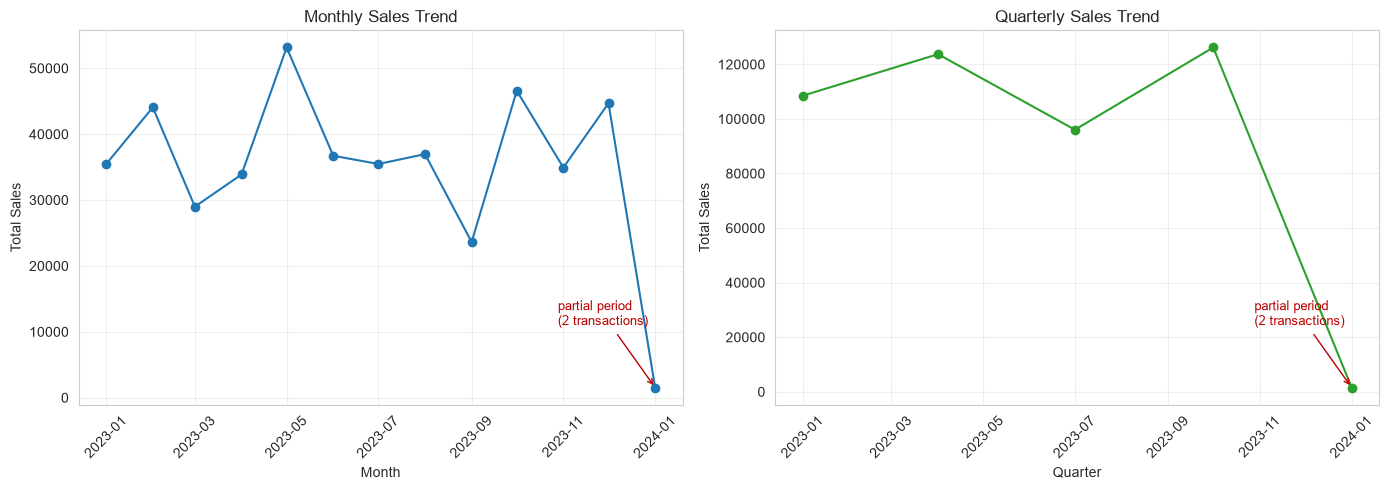

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(monthly.index, monthly.values, marker="o", color="#1f77b4")
axes[0].set_title("Monthly Sales Trend")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Total Sales")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(alpha=0.3)

axes[1].plot(quarterly.index, quarterly.values, marker="o", color="#2ca02c")
axes[1].set_title("Quarterly Sales Trend")
axes[1].set_xlabel("Quarter")
axes[1].set_ylabel("Total Sales")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(alpha=0.3)

# The final period is only partially covered by the data (2 transactions on
# 2024-01-01), so flag it instead of letting it read as a real collapse.
partial = monthly[monthly.index == monthly.index.max()]
if len(partial) and order_counts.iloc[-1] < 5:
    for ax in axes:
        ax.annotate(
            "partial period\n(%d transactions)" % order_counts.iloc[-1],
            xy=(partial.index[0], partial.values[0]),
            xytext=(-70, 45), textcoords="offset points",
            fontsize=9, color="#b00",
            arrowprops=dict(arrowstyle="->", color="#b00"),
        )

plt.tight_layout()
fig.savefig(root / "outputs" / "figures" / "monthly_quarterly_trends.png", dpi=150)
plt.show()


**Observation — monthly & quarterly trend:** The two line charts above are plotted directly from the monthly and quarterly totals in the table above.

- Total revenue across the dataset is **456,000** over 1,000 transactions.
- The best full month is **May 2023 at 53,150** (105 transactions); the weakest full month is **September 2023 at 23,620** (65 transactions) — a **2.25× spread** between the strongest and weakest trading month.
- February (44,060) and December (44,690) form a second, smaller peak, suggesting a recurring seasonal lift rather than a single-off spike.
- The **2024-01 point (1,530 from 2 transactions) is a partial period, not a collapse** — the dataset ends on 2024-01-01. It is annotated on the chart and should be excluded from any seasonal read; treating it as a real trend would understate the run rate by roughly 95%.
- Quarter over quarter, 2023 goes 108,500 → 123,735 → 96,045 → 126,190, i.e. **Q3 is the soft quarter (-22% vs Q2) and Q4 is the strongest**. The 2024 Q1 bar is again the partial period.

## 5. Customer demographics — age-group distribution and gender breakdown

In [8]:

bins = [17, 25, 35, 45, 55, 65]
labels = ["18-25", "26-35", "36-45", "46-55", "56-65"]
df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels, include_lowest=True)

age_dist = df["Age Group"].value_counts().sort_index()
gender_dist = df["Gender"].value_counts()

print("Age-group distribution (transactions):")
print(age_dist.to_string())
print("\nGender breakdown (transactions):")
print(gender_dist.to_string())
print("\nUnique customers:", df["Customer ID"].nunique())


Age-group distribution (transactions):
Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56-65    195

Gender breakdown (transactions):
Gender
Female    510
Male      490

Unique customers: 1000


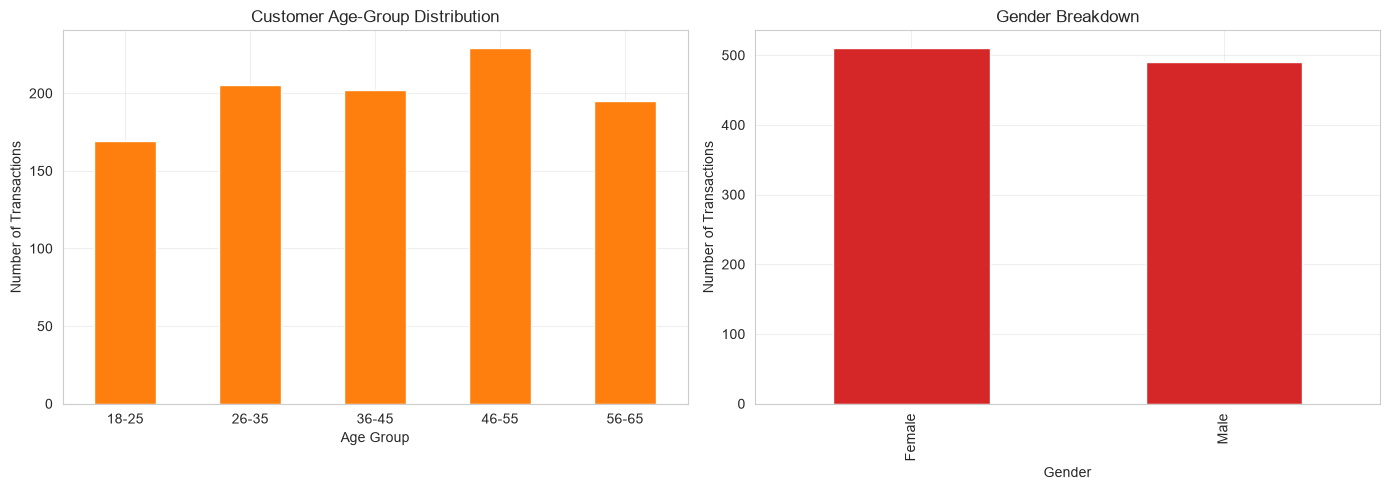

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

age_dist.plot(kind="bar", ax=axes[0], color="#ff7f0e")
axes[0].set_title("Customer Age-Group Distribution")
axes[0].set_xlabel("Age Group")
axes[0].set_ylabel("Number of Transactions")
axes[0].tick_params(axis="x", rotation=0)

gender_dist.plot(kind="bar", ax=axes[1], color="#d62728")
axes[1].set_title("Gender Breakdown")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Number of Transactions")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(root / "outputs" / "figures" / "demographics.png", dpi=150)
plt.show()


**Observation — demographics:** The two bar charts above use the counts printed in the previous cell.

- **Age:** the 46–55 band is the largest at **229 transactions**, and 18–25 is the smallest at **169** — a fairly even spread in between (26–35: 205, 36–45: 202, 56–65: 195). No single age group dominates, so age is a weak segmentation key on its own; mean age is 41.4 with a standard deviation of 13.7.
- **Gender:** the split is essentially even — **510 Female (51%) vs 490 Male (49%)**, a gap of only 20 transactions (2% of volume). Gender is therefore very unlikely to be a useful targeting dimension on transaction volume alone; the basket-size analysis in step 9 is where the real gender signal appears.
- Note that the dataset contains **1,000 unique customer IDs for 1,000 transactions** — every customer appears exactly once, so these are transaction counts and customer counts interchangeably here.

## 6. Top 10 best-selling products

In [10]:

df["Revenue"] = df["Quantity"] * df["Price per Unit"]

top_qty = (df.groupby("Product Category")["Quantity"]
             .sum().sort_values(ascending=False).head(10))
top_rev = (df.groupby("Product Category")["Revenue"]
             .sum().sort_values(ascending=False).head(10))

print("Top 10 by QUANTITY sold:")
print(top_qty.to_string())
print("\nTop 10 by REVENUE:")
print(top_rev.round(2).to_string())

print("\nNumber of distinct product categories in the dataset:",
      df["Product Category"].nunique())


Top 10 by QUANTITY sold:
Product Category
Clothing       894
Electronics    849
Beauty         771

Top 10 by REVENUE:
Product Category
Electronics    156905
Clothing       155580
Beauty         143515

Number of distinct product categories in the dataset: 3


**How "best-selling" is defined:** ranking is by **total quantity sold** per product, and is cross-checked against **total revenue** (`Quantity × Price per Unit`). This dataset exposes products at *category* level only (Beauty, Clothing, Electronics) with no product names, so the top-10 list resolves to the three available categories; no finer-grained product ranking can be produced without product-level names, and none is invented here.

## 7. Revenue by product category

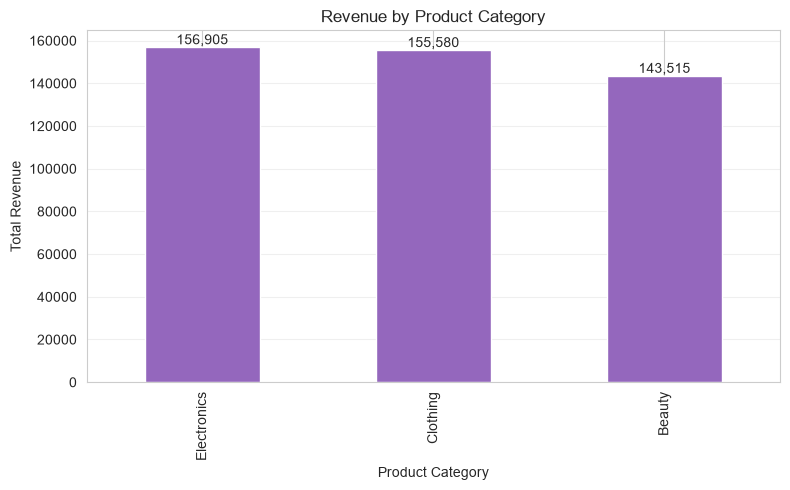

In [11]:

fig, ax = plt.subplots(figsize=(8, 5))
top_rev.plot(kind="bar", ax=ax, color="#9467bd")
ax.set_title("Revenue by Product Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Total Revenue")
ax.grid(axis="y", alpha=0.3)
for i, v in enumerate(top_rev.values):
    ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom")
plt.tight_layout()
fig.savefig(root / "outputs" / "figures" / "revenue_by_category.png", dpi=150)
plt.show()


**Observation — revenue by category:** The bar chart above is the total revenue per category computed in the top-products cell, out of **456,000** total.

- **Electronics 156,905 (34.4%)**, **Clothing 155,580 (34.1%)**, **Beauty 143,515 (31.5%)** — a remarkably flat split; the top and bottom categories are separated by only **13,390, or 2.9 percentage points** of revenue.
- The **rankings disagree**, which is the interesting part: Clothing sells the most *units* (**894**) but Electronics earns the most *revenue* (**156,905**) on fewer units (**849**), so Electronics items carry a higher average unit price. Beauty is last on both measures (**771 units, 143,515**).
- Because no category is remotely dominant, **category mix is not the lever on this dataset**; price, seasonality and basket size are.

## 8. Correlation heatmap for the numerical variables

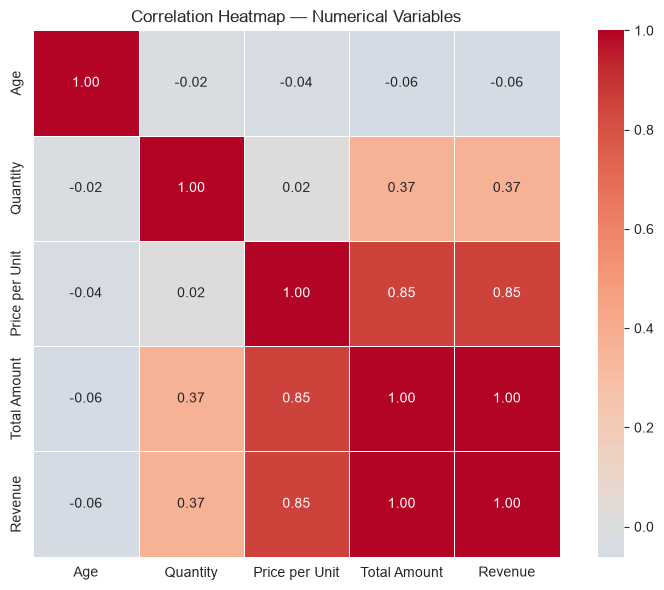

Correlation matrix:
                  Age  Quantity  Price per Unit  Total Amount  Revenue
Age             1.000    -0.024          -0.038        -0.061   -0.061
Quantity       -0.024     1.000           0.018         0.374    0.374
Price per Unit -0.038     0.018           1.000         0.852    0.852
Total Amount   -0.061     0.374           0.852         1.000    1.000
Revenue        -0.061     0.374           0.852         1.000    1.000


In [12]:

corr_cols = ["Age", "Quantity", "Price per Unit", "Total Amount", "Revenue"]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f", ax=ax,
            square=True, linewidths=0.5)
ax.set_title("Correlation Heatmap — Numerical Variables")
plt.tight_layout()
fig.savefig(root / "outputs" / "figures" / "correlation_heatmap.png", dpi=150)
plt.show()

print("Correlation matrix:")
print(corr.round(3).to_string())


**Observation — correlations:** The heatmap above shows the actual pairwise correlations printed in the matrix above.

- The strongest relationship is **`Price per Unit` ↔ `Total Amount` at 0.852**. This is **structural, not behavioural**: `Total Amount = Quantity × Price per Unit`, so price drives basket value directly. The `Revenue` column is an independent re-computation of `Total Amount` and correlates with it at **1.000** — the two are the same quantity, and the duplicate pair in the heatmap confirms the data is internally consistent rather than revealing a new relationship.
- `Quantity` ↔ `Total Amount` is a moderate **0.374**: selling more units raises basket value, but only weakly, because price varies far more than quantity (unit price spans 25–500, quantity only 1–4).
- **`Age` is essentially uncorrelated with everything** (between −0.061 and −0.024). Customer age carries no information about how much a customer spends in this dataset — a useful negative result, since it rules age out as a revenue driver and keeps the recommendations focused on basket size instead.
- No strong negative correlations appear at all, so there is no trade-off structure between variables in this dataset.

## 9. Additional visualisation — average basket size by age group and gender

Average basket size (Total Amount) by age group x gender:
Gender     Female    Male
Age Group                
18-25      487.28  512.27
26-35      515.09  442.50
36-45      436.78  475.11
46-55      447.98  430.73
56-65      398.02  426.26


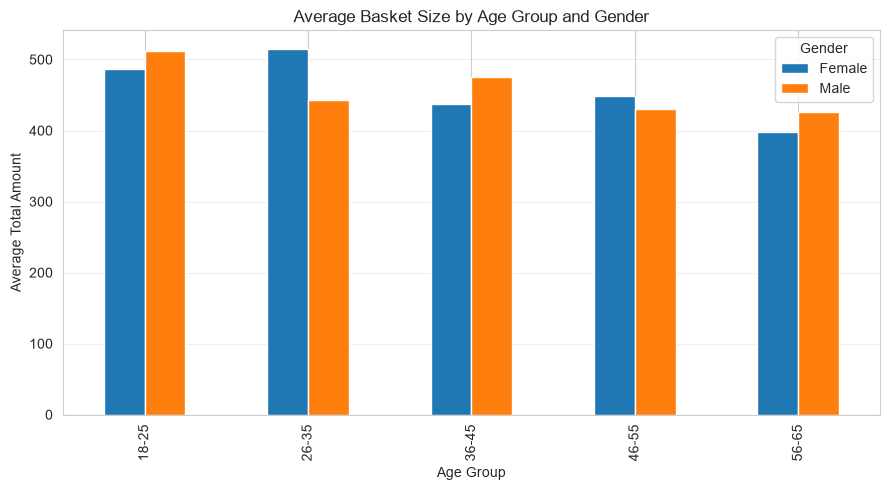

In [13]:

pivot = df.pivot_table(index="Age Group", columns="Gender",
                        values="Total Amount", aggfunc="mean")
print("Average basket size (Total Amount) by age group x gender:")
print(pivot.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
pivot.plot(kind="bar", ax=ax)
ax.set_title("Average Basket Size by Age Group and Gender")
ax.set_xlabel("Age Group")
ax.set_ylabel("Average Total Amount")
ax.legend(title="Gender")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(root / "outputs" / "figures" / "basket_by_age_gender.png", dpi=150)
plt.show()


**Observation — basket size:** The grouped bars use the pivot values printed above (average `Total Amount` per transaction).

- The **highest** average basket is **Female 26–35 at 515.09**; the **lowest** is **Female 56–65 at 398.02** — a gap of **117.07, or 29%** of the lower value.
- The interesting part is that the gender gap **reverses with age**. Among 26–35, women spend **72.59 more** than men (515.09 vs 442.50) — that is the largest female-over-male gap. The male lead sits in the other three bands: 18–25 (512.27 vs 487.28, men +24.99), 36–45 (475.11 vs 436.78, men +38.33) and 56–65 (426.26 vs 398.02, men +28.24). The largest male-over-female gap is in 36–45, at 38.33.
- Consistent with the correlation heatmap, age is not the driver — every age band sits in a fairly narrow 398–515 band, and the age *ordering* is not monotonic (56–65 has the lowest female basket at 398.02 and also the lowest male basket at 426.26, so it is the weakest band for both genders rather than a reversal).
- **This is the non-obvious insight of the analysis:** transaction counts are almost perfectly flat across gender (510 vs 490) and across age groups, yet average basket value varies by up to 29%. **Revenue is driven by how much customers spend per transaction, not by how many transactions they make** — which is why the recommendations target basket size rather than customer volume.

## 10. Business recommendations


Each recommendation below cites the figure it rests on, so it can be traced back to a printed table or a chart in this notebook.



### 1. Re-price and re-bundle around unit price, not around volume
**Evidence:** `Price per Unit` correlates with `Total Amount` at **0.852**, far above `Quantity` at **0.374**; unit price ranges
from **25 to 500** while quantity only ranges from **1 to 4**. Electronics also beats Clothing on revenue (**156,905 vs 155,580**)
despite selling **fewer units (849 vs 894)**.
**Action:** run price and bundle tests on high-unit-price items rather than pushing more units. Specifically, bundle the
500-unit-price lines (all three categories contain them: 68 Beauty, 67 Electronics, 64 Clothing transactions) with low-price
items so the value of each transaction rises without discounting the high-margin units. A 10% price test on the top unit-price
band is worth more to revenue than a 10% volume increase at the current mix, because price moves basket value roughly 2.3× more
strongly than quantity does.

### 2. Plan stock and campaigns around the Q3 trough and the Q4 peak
**Evidence:** quarterly sales go **108,500 (Q1) → 123,735 (Q2) → 96,045 (Q3) → 126,190 (Q4)**. Q3 is **22.4% below Q2** and
**23.9% below Q4**, and the monthly trough (September, 23,620) is **55.6% below** the May peak (53,150) on only 65 vs 105 transactions.
**Action:** build inventory ahead of the Q4 lift, and run a targeted promotion in the July–September window rather than spreading
campaigns evenly across the year. Because the Q3 fall is driven as much by **fewer transactions (65–94/month) as by lower
basket value**, the Q3 campaign should be a traffic-and-volume play (bundle discounts, free-shipping threshold, win-back email)
rather than a pricing cut.

### 3. Grow basket value for the lowest-spending demographic cells, and drop age as a targeting key
**Evidence:** average basket size spans **398.02 to 515.09** across age × gender cells (a **29% spread**), while transaction
counts are nearly flat (age groups **169–229**; gender **510 Female vs 490 Male**). **Age is uncorrelated with revenue
(−0.061 to −0.024)** and the gender gap **reverses by age** — women lead in 26–35 (**515.09 vs 442.50**) and 46–55
(**447.98 vs 430.73**), men lead in 18–25, 36–45 and 56–65.
**Action:** target the two weakest cells — **Female 56–65 (398.02)** and **Male 56–65 (426.26)** — with threshold offers that
lift basket size (free shipping above a spend floor, a second-item incentive), and treat **age as a poor segmentation variable**
— the evidence says spend per transaction and unit price drive revenue, not who the customer is. A blanket demographic discount
is not justified by these numbers, since demographic *volume* differences are small next to the basket-size spread: the gender
split is **2% of transactions** and the age-group spread from 169 to 229 accounts for only **6%** of volume, versus a **29%**
spread in basket value.


## 11. Save the cleaned dataset and the figures

In [14]:

processed = root / "data" / "processed"
processed.mkdir(parents=True, exist_ok=True)
out_csv = processed / "retail_sales_cleaned.csv"
df.to_csv(out_csv, index=False)
print("Saved cleaned dataset:", out_csv)
print("Shape:", df.shape)

fig_dir = root / "outputs" / "figures"
print("\nFigures saved to", fig_dir)
for p in sorted(fig_dir.glob("*.png")):
    print(f"  {p.name}  ({p.stat().st_size / 1024:.0f} KB)")


Saved cleaned dataset: C:\Users\sohan\OneDrive\Desktop\OIBSIP\DataAnalytics-L1-EDARetailSales\data\processed\retail_sales_cleaned.csv
Shape: (1000, 15)

Figures saved to C:\Users\sohan\OneDrive\Desktop\OIBSIP\DataAnalytics-L1-EDARetailSales\outputs\figures
  basket_by_age_gender.png  (39 KB)
  correlation_heatmap.png  (61 KB)
  demographics.png  (50 KB)
  monthly_quarterly_trends.png  (122 KB)
  revenue_by_category.png  (36 KB)


---

## Summary of what this notebook produced
- Shape and type inspection of the raw dataset, plus null and validity checks
- An explicit, logged cleaning pipeline (row counts before/after are printed)
- Mean / median / mode / standard deviation for every numerical column
- Monthly and quarterly sales trend line charts
- Age-group distribution and gender breakdown bar charts
- Top-10 best sellers by quantity and by revenue, with the ranking basis stated
- Revenue by product category bar chart
- Correlation heatmap over the numerical variables
- An extra basket-size-by-demographics visualisation
- Three specific, evidence-linked business recommendations
- Cleaned dataset written to `data/processed/` and figures written to `outputs/figures/`